In [ ]:
import requests
import pandas as pd

url = "https://data.sec.gov/api/xbrl/companyfacts/CIK0001769628.json"

headers = {
    "User-Agent": "CoreWeave Financial Analysis cpierrelouis310@gmail.com"
}

response = requests.get(url, headers=headers, timeout=30)
response.raise_for_status()

data = response.json()

print("Company:", data["entityName"])
print("Available categories:", data["facts"].keys())


Company: CoreWeave, Inc.
Available categories: dict_keys(['us-gaap', 'dei', 'ecd', 'ffd'])


In [ ]:

# Access US GAAP financial metrics
facts = data["facts"]["us-gaap"]

# Search for financial metrics relevant to our analysis
keywords = ["Revenue", "OperatingExpenses", "OperatingIncome",
    "InterestExpense",
    "NetIncome"
]

for tag, details in facts.items():
    if any(keyword.lower() in tag.lower() for keyword in keywords):
        print(tag, ":", details.get("label"))


ContractWithCustomerLiabilityRevenueRecognized : Contract with Customer, Liability, Revenue Recognized
InterestExpenseDebt : Interest Expense, Debt
InterestExpenseDebtExcludingAmortization : Interest Expense, Debt, Excluding Amortization
NetIncomeLoss : Net Income (Loss) Attributable to Parent
NetIncomeLossAvailableToCommonStockholdersBasic : Net Income (Loss) Available to Common Stockholders, Basic
NetIncomeLossAvailableToCommonStockholdersDiluted : Net Income (Loss) Available to Common Stockholders, Diluted
OperatingIncomeLoss : Operating Income (Loss)
OtherNonoperatingIncomeExpense : Other Nonoperating Income (Expense)
RevenueFromContractWithCustomerExcludingAssessedTax : Revenue from Contract with Customer, Excluding Assessed Tax
RevenueRemainingPerformanceObligation : Revenue, Remaining Performance Obligation, Amount
FinanceLeaseInterestExpense : Finance Lease, Interest Expense


In [ ]:

# Select CoreWeave's revenue metric
revenue = facts[
    "RevenueFromContractWithCustomerExcludingAssessedTax"
]

# Extract observations reported in USD
revenue_data = revenue["units"]["USD"]

# Convert JSON observations into a pandas DataFrame
revenue_df = pd.DataFrame(revenue_data)

# Display relevant columns
revenue_df[
    ["start", "end", "val", "form", "fy", "fp", "filed"]
].head(15)


,start,end,val,form,fy,fp,filed
0,2023-01-01,2023-12-31,229000000,10-K,2025,FY,2026-03-02
1,2024-01-01,2024-03-31,188684000,10-Q,2025,Q1,2025-05-15
2,2024-01-01,2024-06-30,584055000,10-Q,2025,Q2,2025-08-13
3,2024-04-01,2024-06-30,395371000,10-Q,2025,Q2,2025-08-13
4,2024-01-01,2024-09-30,1167996000,10-Q,2025,Q3,2025-11-13
5,2024-07-01,2024-09-30,583941000,10-Q,2025,Q3,2025-11-13
6,2024-01-01,2024-12-31,1915000000,10-K,2025,FY,2026-03-02
7,2025-01-01,2025-03-31,981632000,10-Q,2025,Q1,2025-05-15
8,2025-01-01,2025-03-31,982000000,10-Q,2026,Q1,2026-05-08
9,2025-01-01,2025-06-30,2194420000,10-Q,2025,Q2,2025-08-13


In [ ]:

# Convert reporting dates into datetime format
revenue_df["start"] = pd.to_datetime(revenue_df["start"])
revenue_df["end"] = pd.to_datetime(revenue_df["end"])

# Calculate reporting period length
revenue_df["period_days"] = (
    revenue_df["end"] - revenue_df["start"]
).dt.days + 1

# Keep annual revenue observations
annual_revenue = revenue_df[
    (revenue_df["form"] == "10-K") &
    (revenue_df["period_days"].between(365, 366))
].copy()

# Extract the actual reporting year
annual_revenue["year"] = annual_revenue["end"].dt.year

# Keep 2023–2025 and the latest filing for each year
annual_revenue = (
    annual_revenue[
        annual_revenue["year"].between(2023, 2025)
    ]
    .sort_values("filed")
    .drop_duplicates(subset=["year"], keep="last")
    .sort_values("year")
)

# Convert dollars to millions
annual_revenue["revenue_millions"] = (
    annual_revenue["val"] / 1_000_000
)

print(
    annual_revenue[
        ["year", "revenue_millions", "filed"]
    ].to_string(index=False)
)


 year  revenue_millions      filed
 2023             229.0 2026-03-02
 2024            1915.0 2026-03-02
 2025            5131.0 2026-03-02


In [ ]:

# Calculate year-over-year revenue growth
annual_revenue["yoy_growth_pct"] = (
    annual_revenue["revenue_millions"].pct_change() * 100
)

# Calculate cumulative revenue
total_revenue = annual_revenue["revenue_millions"].sum()

print(
    annual_revenue[
        ["year", "revenue_millions", "yoy_growth_pct"]
    ].round(2).to_string(index=False)
)

print(f"\nTotal revenue (2023–2025): ${total_revenue:,.0f}M")


 year  revenue_millions  yoy_growth_pct
 2023             229.0             NaN
 2024            1915.0          736.24
 2025            5131.0          167.94

Total revenue (2023–2025): $7,275M


In [ ]:

def extract_annual_metric(tag, metric_name):
    # Retrieve the metric's observations
    observations = facts[tag]["units"]["USD"]

    # Convert observations to a DataFrame
    df = pd.DataFrame(observations)

    # Standardize dates
    df["start"] = pd.to_datetime(df["start"])
    df["end"] = pd.to_datetime(df["end"])

    # Calculate reporting period length
    df["period_days"] = (
        df["end"] - df["start"]
    ).dt.days + 1

    # Select annual observations from 10-K filings
    df = df[
        (df["form"] == "10-K") &
        (df["period_days"].between(365, 366))
    ].copy()

    # Identify the actual reporting year
    df["year"] = df["end"].dt.year

    # Keep 2023–2025 and remove duplicate periods
    df = (
        df[df["year"].between(2023, 2025)]
        .sort_values("filed")
        .drop_duplicates(subset=["year"], keep="last")
        .sort_values("year")
    )

    # Convert to USD millions
    df[metric_name] = df["val"] / 1_000_000

    return df[["year", metric_name]]


# Extract operating income and net income
operating_income = extract_annual_metric(
    "OperatingIncomeLoss",
    "operating_income_millions"
)

net_income = extract_annual_metric(
    "NetIncomeLoss",
    "net_income_millions"
)

# Extract interest expense on debt
interest_expense = extract_annual_metric(
    "InterestExpenseDebt",
    "interest_expense_millions"
)

# Combine the datasets using reporting year
financials = (
    annual_revenue[["year", "revenue_millions"]]
    .merge(operating_income, on="year", how="left")
    .merge(net_income, on="year", how="left")
    .merge(interest_expense, on="year", how="left")
)

print(financials.to_string(index=False))


 year  revenue_millions  operating_income_millions  net_income_millions  interest_expense_millions
 2023             229.0                      -14.0               -594.0                       27.0
 2024            1915.0                      324.0               -863.0                      349.0
 2025            5131.0                      -46.0              -1167.0                     1148.0


In [ ]:
financials["operating_margin_pct"] = financials["operating_margin_pct"] = (
    financials["operating_income_millions"]
    / financials["revenue_millions"]
) * 100

print(financials[["year", "operating_margin_pct"]].round(2))


   year  operating_margin_pct
0  2023                 -6.11
1  2024                 16.92
2  2025                 -0.90


In [ ]:

# Net profit margin
financials["net_margin_pct"] = (
    financials["net_income_millions"]
    / financials["revenue_millions"]
) * 100

# Debt interest expense as a percentage of revenue
financials["interest_to_revenue_pct"] = (
    financials["interest_expense_millions"]
    / financials["revenue_millions"]
) * 100

# Display financial ratios
print(
    financials[
        ["year", "operating_margin_pct",
         "net_margin_pct", "interest_to_revenue_pct"]
    ].round(2).to_string(index=False)
)


 year  operating_margin_pct  net_margin_pct  interest_to_revenue_pct
 2023                 -6.11         -259.39                    11.79
 2024                 16.92          -45.07                    18.22
 2025                 -0.90          -22.74                    22.37


In [ ]:
annual_costs = pd.DataFrame({
    "year": [2023, 2024, 2025],
    "cost_of_revenue_millions": [69, 493, 1453],
    "technology_infrastructure_millions": [131, 961, 2929],
    "sales_marketing_millions": [13, 18, 144],
    "general_administrative_millions": [30, 119, 651],
    "net_interest_expense_millions": [28, 361, 1229],
}).set_index("year")

annual = financials.copy()
annual["year"] = annual["year"].astype(int)
annual = annual.set_index("year", verify_integrity=True).sort_index()
assert annual.index.tolist() == [2023, 2024, 2025]

annual[annual_costs.columns] = annual_costs
annual["net_margin_pct"] = 100 * annual["net_income_millions"] / annual["revenue_millions"]
annual["net_interest_to_revenue_pct"] = (
    100 * annual["net_interest_expense_millions"] / annual["revenue_millions"]
)

cost_columns = annual_costs.columns.drop("net_interest_expense_millions")
cost_drivers = annual.loc[2024:2025, cost_columns].T
cost_drivers["increase_millions"] = cost_drivers[2025] - cost_drivers[2024]

display(annual[["net_margin_pct", "net_interest_to_revenue_pct"]].round(2))
display(cost_drivers.sort_values("increase_millions", ascending=False))


,net_margin_pct,net_interest_to_revenue_pct
year,,
2023,-259.39,12.23
2024,-45.07,18.85
2025,-22.74,23.95


year,2024,2025,increase_millions
technology_infrastructure_millions,961,2929,1968
cost_of_revenue_millions,493,1453,960
general_administrative_millions,119,651,532
sales_marketing_millions,18,144,126


In [ ]:
cost_pct = annual[cost_columns].div(annual["revenue_millions"], axis=0) * 100
display(cost_pct.round(1))

,cost_of_revenue_millions,technology_infrastructure_millions,sales_marketing_millions,general_administrative_millions
year,,,,
2023,30.1,57.2,5.7,13.1
2024,25.7,50.2,0.9,6.2
2025,28.3,57.1,2.8,12.7


In [ ]:

# Calculate net profit margin
financials["net_margin_pct"] = (
    financials["net_income_millions"]
    / financials["revenue_millions"]
) * 100

# Calculate debt interest expense as a percentage of revenue
financials["interest_to_revenue_pct"] = (
    financials["interest_expense_millions"]
    / financials["revenue_millions"]
) * 100

# Display the results
print(financials.round(2).to_string(index=False))


 year  revenue_millions  operating_income_millions  net_income_millions  interest_expense_millions  operating_margin_pct  net_margin_pct  interest_to_revenue_pct
 2023             229.0                      -14.0               -594.0                       27.0                 -6.11         -259.39                    11.79
 2024            1915.0                      324.0               -863.0                      349.0                 16.92          -45.07                    18.22
 2025            5131.0                      -46.0              -1167.0                     1148.0                 -0.90          -22.74                    22.37


In [ ]:
# NEXT step 10-Q

def extract_quarterly_metric(tag, metric_name):
    # Retrieve financial observations
    df = pd.DataFrame(facts[tag]["units"]["USD"])

    # Convert dates
    df["start"] = pd.to_datetime(df["start"])
    df["end"] = pd.to_datetime(df["end"])

    # Calculate reporting period length
    df["period_days"] = (
        df["end"] - df["start"]
    ).dt.days + 1

    # Keep individual quarters from 10-Q filings
    df = df[
        (df["form"] == "10-Q") &
        (df["period_days"].between(80, 100))
    ].copy()

    # Identify calendar year and quarter
    df["year"] = df["end"].dt.year
    df["quarter"] = df["end"].dt.quarter

    # Keep the latest reported value per quarter
    df = (
        df.sort_values("filed")
        .drop_duplicates(
            subset=["year", "quarter"],
            keep="last"
        )
        .sort_values(["year", "quarter"])
    )

    # Convert USD to millions
    df[metric_name] = df["val"] / 1_000_000

    return df[["year", "quarter", metric_name]]


quarterly_revenue = extract_quarterly_metric(
    "RevenueFromContractWithCustomerExcludingAssessedTax",
    "revenue_millions"
)

quarterly_operating = extract_quarterly_metric(
    "OperatingIncomeLoss",
    "operating_income_millions"
)

quarterly_net = extract_quarterly_metric(
    "NetIncomeLoss",
    "net_income_millions"
)

quarterly_interest = extract_quarterly_metric(
    "InterestExpenseDebt",
    "interest_expense_millions"
)

quarterly = (
    quarterly_revenue
    .merge(quarterly_operating, on=["year", "quarter"], how="outer")
    .merge(quarterly_net, on=["year", "quarter"], how="outer")
    .merge(quarterly_interest, on=["year", "quarter"], how="outer")
    .sort_values(["year", "quarter"])
)

print(quarterly.to_string(index=False))



 year  quarter  revenue_millions  operating_income_millions  net_income_millions  interest_expense_millions
 2024        1           188.684                     16.847             -129.248                     40.503
 2024        2           395.371                     77.721             -323.021                     67.097
 2024        3           583.941                    117.116             -359.807                    102.328
 2025        1           982.000                    -27.000             -315.000                    257.000
 2025        2          1212.000                     19.000             -290.000                    256.000
 2025        3          1365.000                     52.000             -110.000                    283.000
 2026        1          2078.000                   -144.000             -740.000                    427.000
 2026        2          2575.000                    -49.000             -626.000                    558.000
 2026        3          3661

In [ ]:

# Financial metrics to calculate
metrics = [
    "revenue_millions",
    "operating_income_millions",
    "net_income_millions",
    "interest_expense_millions"
]

# Calculate Q4 using annual totals minus Q1–Q3
q4_rows = []

for year in [2024, 2025]:
    annual = financials.loc[financials["year"] == year, metrics].iloc[0]
    first_nine_months = quarterly.loc[
        (quarterly["year"] == year) &
        (quarterly["quarter"].isin([1, 2, 3])),
        metrics
    ].sum()

    q4 = (annual - first_nine_months).to_dict()
    q4["year"] = year
    q4["quarter"] = 4
    q4_rows.append(q4)

# Add Q4 to our quarterly dataset
quarterly_complete = pd.concat(
    [quarterly, pd.DataFrame(q4_rows)],
    ignore_index=True
).sort_values(["year", "quarter"])

print(quarterly_complete.round(3).to_string(index=False))


 year  quarter  revenue_millions  operating_income_millions  net_income_millions  interest_expense_millions
 2024        1           188.684                     16.847             -129.248                     40.503
 2024        2           395.371                     77.721             -323.021                     67.097
 2024        3           583.941                    117.116             -359.807                    102.328
 2024        4           747.004                    112.316              -50.924                    139.072
 2025        1           982.000                    -27.000             -315.000                    257.000
 2025        2          1212.000                     19.000             -290.000                    256.000
 2025        3          1365.000                     52.000             -110.000                    283.000
 2025        4          1572.000                    -90.000             -452.000                    352.000
 2026        1          2078

In [ ]:

# Financial metrics to calculate
metrics = [
    "revenue_millions",
    "operating_income_millions",
    "net_income_millions",
    "interest_expense_millions"
]

# Calculate Q4 using annual totals minus Q1–Q3
q4_rows = []

for year in [2024, 2025]:
    annual = financials.loc[financials["year"] == year, metrics].iloc[0]
    first_nine_months = quarterly.loc[
        (quarterly["year"] == year) &
        (quarterly["quarter"].isin([1, 2, 3])),
        metrics
    ].sum()

    q4 = (annual - first_nine_months).to_dict()
    q4["year"] = year
    q4["quarter"] = 4
    q4_rows.append(q4)

# Add Q4 to our quarterly dataset
quarterly_complete = pd.concat(
    [quarterly, pd.DataFrame(q4_rows)],
    ignore_index=True
).sort_values(["year", "quarter"])

print(quarterly_complete.round(3).to_string(index=False))


 year  quarter  revenue_millions  operating_income_millions  net_income_millions  interest_expense_millions
 2024        1           188.684                     16.847             -129.248                     40.503
 2024        2           395.371                     77.721             -323.021                     67.097
 2024        3           583.941                    117.116             -359.807                    102.328
 2024        4           747.004                    112.316              -50.924                    139.072
 2025        1           982.000                    -27.000             -315.000                    257.000
 2025        2          1212.000                     19.000             -290.000                    256.000
 2025        3          1365.000                     52.000             -110.000                    283.000
 2025        4          1572.000                    -90.000             -452.000                    352.000
 2026        1          2078

In [ ]:

# validating the data
quarterly_totals = (
    quarterly_complete[
        quarterly_complete["year"].isin([2024, 2025])
    ]
    .groupby("year")[metrics]
    .sum()
)

annual_totals = financials.set_index("year").loc[
    [2024, 2025], metrics
]

# Calculate any differences
differences = quarterly_totals - annual_totals

print("RECONCILIATION DIFFERENCES (USD millions)")
print(differences.round(3))


RECONCILIATION DIFFERENCES (USD millions)
      revenue_millions  operating_income_millions  net_income_millions  \
year                                                                     
2024               0.0                        0.0                  0.0   
2025               0.0                        0.0                  0.0   

      interest_expense_millions  
year                             
2024                        0.0  
2025                        0.0  


In [ ]:

quarterly_complete.to_csv(
    "coreweave_quarterly_financials.csv",
    index=False
)



In [ ]:

expense_tags = [
    "CostOfGoodsAndServicesSold",
    "GeneralAndAdministrativeExpense",
    "SellingAndMarketingExpense",
    "ResearchAndDevelopmentExpense",
    "DepreciationDepletionAndAmortization"
]

for tag in expense_tags:
    df = pd.DataFrame(facts[tag]["units"]["USD"])

    quarterly_records = df[
        (df["form"] == "10-Q") &
        (df["start"].notna())
    ]

    print(f"{tag}: {len(quarterly_records)} records")


CostOfGoodsAndServicesSold: 20 records
GeneralAndAdministrativeExpense: 20 records
SellingAndMarketingExpense: 20 records
ResearchAndDevelopmentExpense: 20 records
DepreciationDepletionAndAmortization: 12 records


In [ ]:

expense_metrics = {
    "CostOfGoodsAndServicesSold": "cost_of_revenue_millions",
    "GeneralAndAdministrativeExpense": "ga_expense_millions",
    "SellingAndMarketingExpense": "sales_marketing_millions",
    "ResearchAndDevelopmentExpense": "rd_expense_millions",
    "DepreciationDepletionAndAmortization": "depreciation_amortization_millions"
}

# Start with the quarterly financial dataset
expense_analysis = quarterly_complete.copy()

# Extract and merge each expense category
for tag, column in expense_metrics.items():
    expense_df = extract_quarterly_metric(tag, column)

    expense_analysis = expense_analysis.merge(
        expense_df,
        on=["year", "quarter"],
        how="left"
    )

# Display expense data
columns = [
    "year",
    "quarter",
    "revenue_millions",
    *expense_metrics.values()
]

print(expense_analysis[columns].round(2).to_string(index=False))


 year  quarter  revenue_millions  cost_of_revenue_millions  ga_expense_millions  sales_marketing_millions  rd_expense_millions  depreciation_amortization_millions
 2024        1            188.68                     59.22                15.69                      4.05                  9.0                               79.51
 2024        2            395.37                    108.84                21.75                      4.17                 12.0                                 NaN
 2024        3            583.94                    143.13                33.63                      4.55                 14.0                                 NaN
 2024        4            747.00                       NaN                  NaN                       NaN                  NaN                                 NaN
 2025        1            982.00                    262.00               175.00                     11.00                 70.0                              443.00
 2025        2        

In [ ]:

# Calculate total operating costs
expense_analysis["total_operating_costs"] = (
    expense_analysis["revenue_millions"]
    - expense_analysis["operating_income_millions"]
)

# Add the expense categories we identified
known_costs = [
    "cost_of_revenue_millions",
    "ga_expense_millions",
    "sales_marketing_millions",
    "rd_expense_millions"
]

expense_analysis["identified_costs"] = (
    expense_analysis[known_costs].sum(axis=1, min_count=4)
)

# Calculate costs not yet explained
expense_analysis["unexplained_costs"] = (
    expense_analysis["total_operating_costs"]
    - expense_analysis["identified_costs"]
)

# Show quarters with complete expense data
results = expense_analysis[
    ["year", "quarter", "total_operating_costs",
     "identified_costs", "unexplained_costs"]
]

print(results.round(2).to_string(index=False))


 year  quarter  total_operating_costs  identified_costs  unexplained_costs
 2024        1                 171.84             87.96              83.88
 2024        2                 317.65            146.76             170.89
 2024        3                 466.83            195.32             271.51
 2024        4                 634.69               NaN                NaN
 2025        1                1009.00            518.00             491.00
 2025        2                1193.00            603.00             590.00
 2025        3                1313.00            659.00             654.00
 2025        4                1662.00               NaN                NaN
 2026        1                2222.00           1053.00            1169.00
 2026        2                2624.00           1234.00            1390.00
 2026        3                3454.00           1583.00            1871.00


In [ ]:

# Calculate technology and infrastructure expenses
expense_analysis["technology_infrastructure_millions"] = (
    expense_analysis["total_operating_costs"]
    - expense_analysis["cost_of_revenue_millions"]
    - expense_analysis["ga_expense_millions"]
    - expense_analysis["sales_marketing_millions"]
)

# Select financial drivers for forecasting
forecast_data = expense_analysis[
    [
        "year",
        "quarter",
        "revenue_millions",
        "cost_of_revenue_millions",
        "technology_infrastructure_millions",
        "ga_expense_millions",
        "sales_marketing_millions",
        "operating_income_millions",
        "interest_expense_millions",
        "net_income_millions"
    ]
].copy()

print(forecast_data.round(2).to_string(index=False))


 year  quarter  revenue_millions  cost_of_revenue_millions  technology_infrastructure_millions  ga_expense_millions  sales_marketing_millions  operating_income_millions  interest_expense_millions  net_income_millions
 2024        1            188.68                     59.22                               92.88                15.69                      4.05                      16.85                      40.50              -129.25
 2024        2            395.37                    108.84                              182.89                21.75                      4.17                      77.72                      67.10              -323.02
 2024        3            583.94                    143.13                              285.51                33.63                      4.55                     117.12                     102.33              -359.81
 2024        4            747.00                       NaN                                 NaN                  NaN                 

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

# Use the existing quarterly financial dataset
dashboard = expense_analysis.copy()

dashboard["period"] = (
    "Q" + dashboard["quarter"].astype(str)
    + " " + dashboard["year"].astype(str)
)

dashboard["operating_margin_pct"] = (
    dashboard["operating_income_millions"]
    / dashboard["revenue_millions"] * 100
)

dashboard["net_margin_pct"] = (
    dashboard["net_income_millions"]
    / dashboard["revenue_millions"] * 100
)

dashboard = dashboard.sort_values(
    ["year", "quarter"]
).reset_index(drop=True)

print(dashboard[[
    "period",
    "revenue_millions",
    "operating_margin_pct",
    "net_margin_pct"
]].round(2).to_string(index=False))


 period  revenue_millions  operating_margin_pct  net_margin_pct
Q1 2024            188.68                  8.93          -68.50
Q2 2024            395.37                 19.66          -81.70
Q3 2024            583.94                 20.06          -61.62
Q4 2024            747.00                 15.04           -6.82
Q1 2025            982.00                 -2.75          -32.08
Q2 2025           1212.00                  1.57          -23.93
Q3 2025           1365.00                  3.81           -8.06
Q4 2025           1572.00                 -5.73          -28.75
Q1 2026           2078.00                 -6.93          -35.61
Q2 2026           2575.00                 -1.90          -24.31
Q3 2026           3661.00                  5.65          -19.37


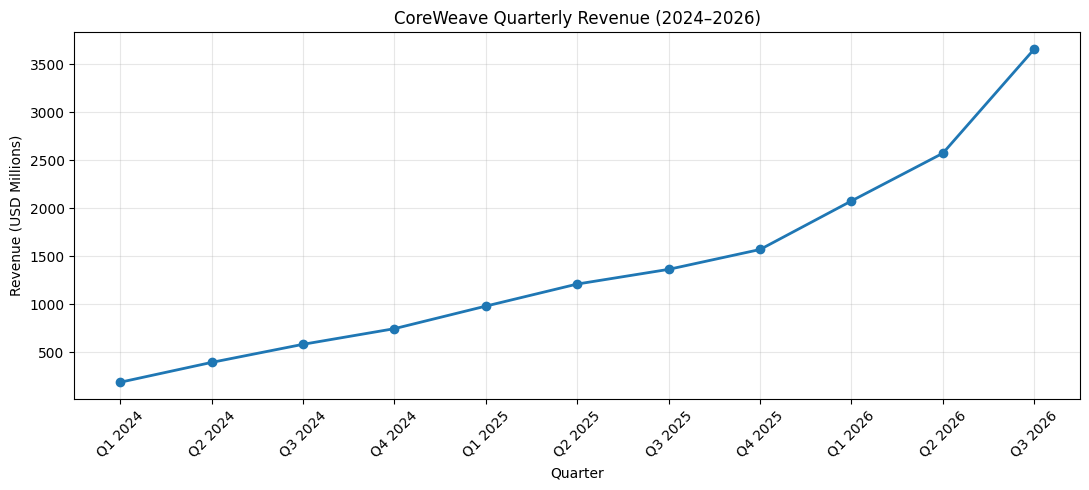

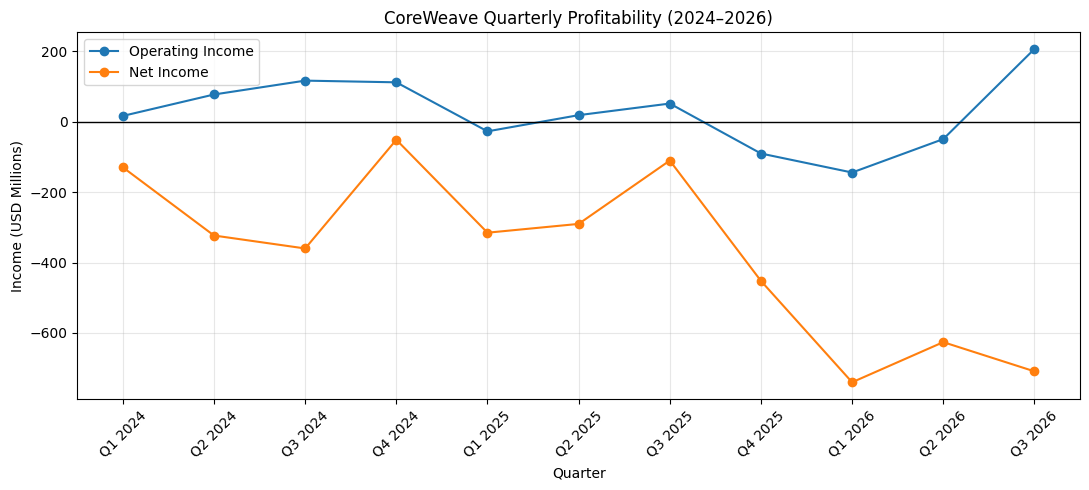

In [ ]:

# Chart 1: Quarterly Revenue
plt.figure(figsize=(11, 5))

plt.plot(
    dashboard["period"],
    dashboard["revenue_millions"],
    marker="o",
    linewidth=2
)

plt.title("CoreWeave Quarterly Revenue (2024–2026)")
plt.xlabel("Quarter")
plt.ylabel("Revenue (USD Millions)")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# Chart 2: Operating Income vs Net Income
plt.figure(figsize=(11, 5))

plt.plot(
    dashboard["period"],
    dashboard["operating_income_millions"],
    marker="o",
    label="Operating Income"
)

plt.plot(
    dashboard["period"],
    dashboard["net_income_millions"],
    marker="o",
    label="Net Income"
)

plt.axhline(0, color="black", linewidth=1)

plt.title("CoreWeave Quarterly Profitability (2024–2026)")
plt.xlabel("Quarter")
plt.ylabel("Income (USD Millions)")
plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


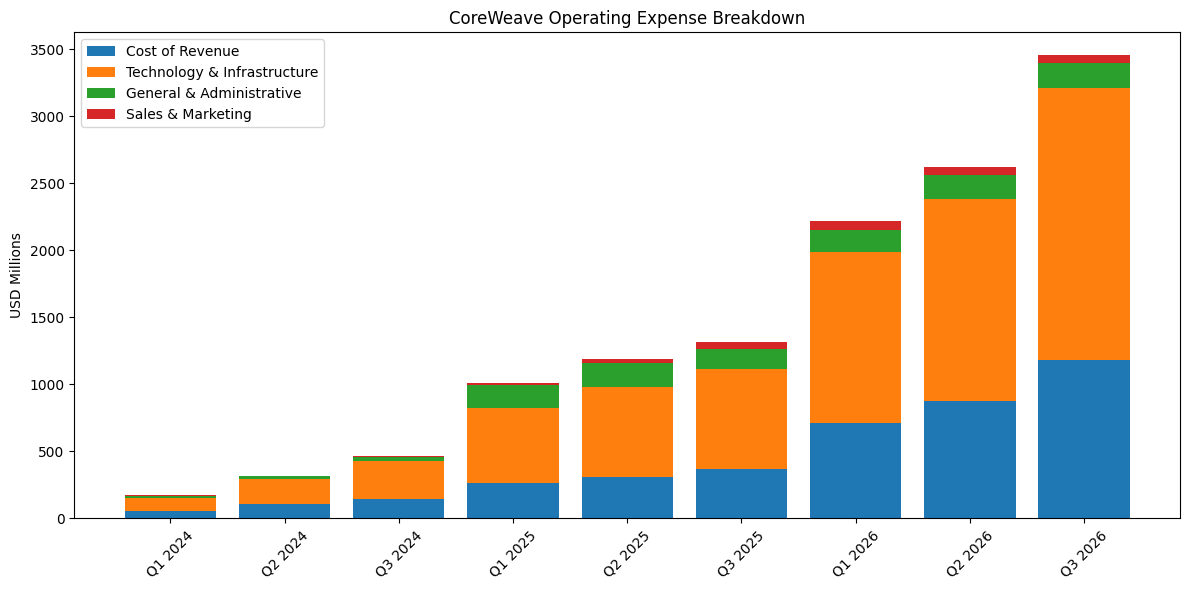

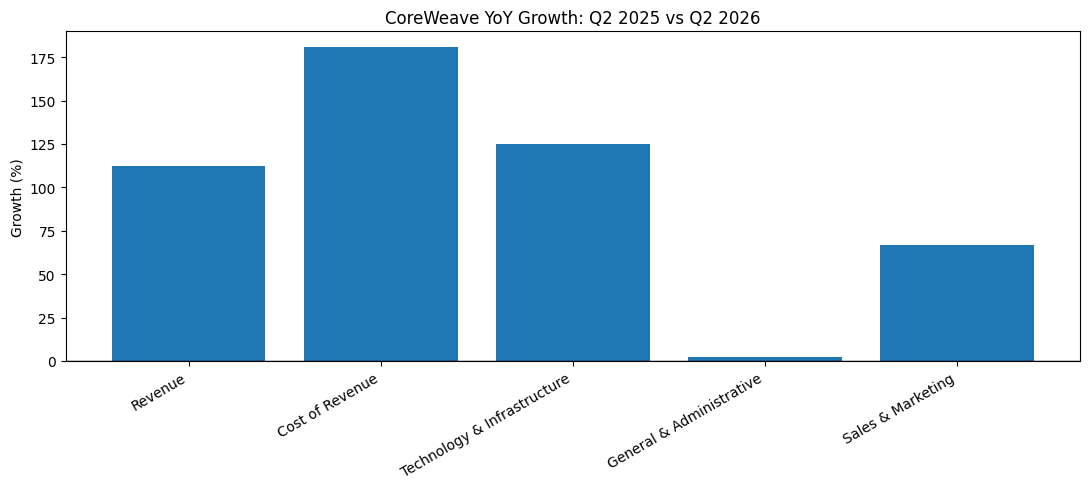

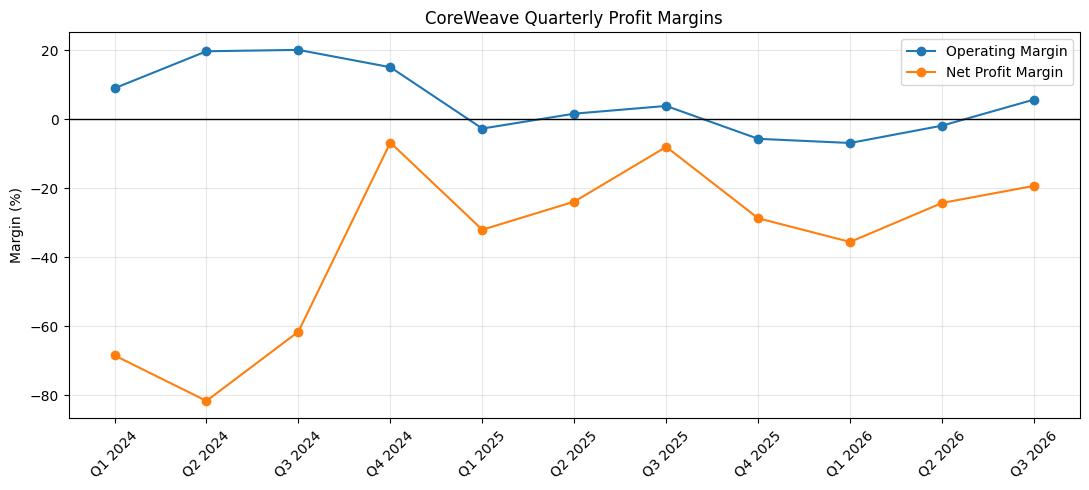

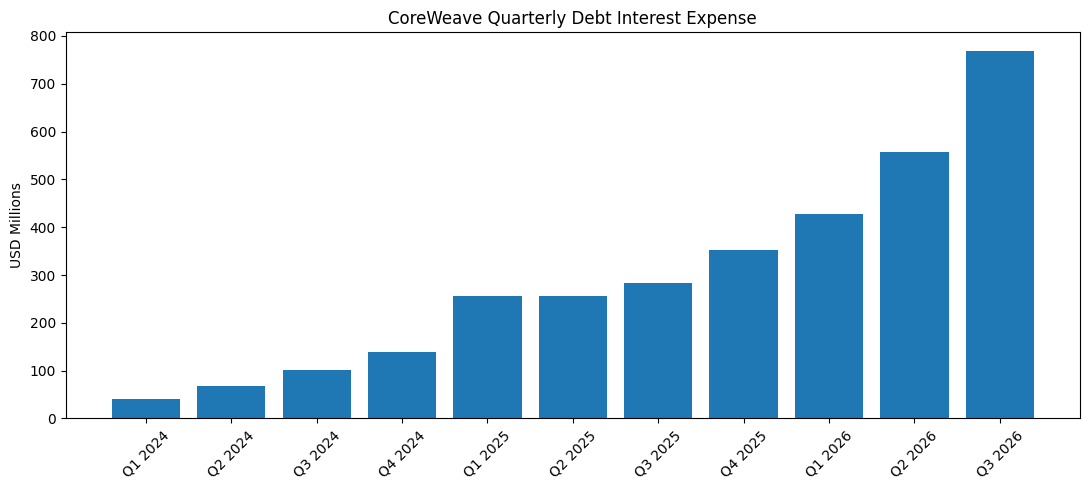

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

dashboard = dashboard.sort_values(
    ["year", "quarter"]
).copy()

# Derive technology infrastructure expense
# from the reported operating expense structure.
dashboard["technology_infrastructure_millions"] = (
    dashboard["revenue_millions"]
    - dashboard["operating_income_millions"]
    - dashboard["cost_of_revenue_millions"]
    - dashboard["ga_expense_millions"]
    - dashboard["sales_marketing_millions"]
)

# CHART 3: Operating Expense Breakdown
expense_columns = [
    "cost_of_revenue_millions",
    "technology_infrastructure_millions",
    "ga_expense_millions",
    "sales_marketing_millions"
]

expense_labels = [
    "Cost of Revenue",
    "Technology & Infrastructure",
    "General & Administrative",
    "Sales & Marketing"
]

complete = dashboard.dropna(
    subset=expense_columns
).copy()

fig, ax = plt.subplots(figsize=(12, 6))
bottom = np.zeros(len(complete))

for column, label in zip(expense_columns, expense_labels):
    values = complete[column].to_numpy()
    ax.bar(complete["period"], values,
           bottom=bottom, label=label)
    bottom += values

ax.set_title("CoreWeave Operating Expense Breakdown")
ax.set_ylabel("USD Millions")
ax.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# CHART 4: Year-over-Year Expense Growth
# Compare Q2 2025 with Q2 2026.
q2_2025 = dashboard.query(
    "year == 2025 and quarter == 2"
).iloc[0]

q2_2026 = dashboard.query(
    "year == 2026 and quarter == 2"
).iloc[0]

growth_columns = [
    "revenue_millions",
    *expense_columns
]

growth_labels = [
    "Revenue",
    *expense_labels
]

growth_rates = [
    (q2_2026[col] / q2_2025[col] - 1) * 100
    for col in growth_columns
]

plt.figure(figsize=(11, 5))
plt.bar(growth_labels, growth_rates)
plt.title("CoreWeave YoY Growth: Q2 2025 vs Q2 2026")
plt.ylabel("Growth (%)")
plt.xticks(rotation=30, ha="right")
plt.axhline(0, color="black", linewidth=1)
plt.tight_layout()
plt.show()


# CHART 5: Profit Margins
plt.figure(figsize=(11, 5))

plt.plot(
    dashboard["period"],
    dashboard["operating_margin_pct"],
    marker="o",
    label="Operating Margin"
)

plt.plot(
    dashboard["period"],
    dashboard["net_margin_pct"],
    marker="o",
    label="Net Profit Margin"
)

plt.axhline(0, color="black", linewidth=1)
plt.title("CoreWeave Quarterly Profit Margins")
plt.ylabel("Margin (%)")
plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# CHART 6: Interest Expense
plt.figure(figsize=(11, 5))

plt.bar(
    dashboard["period"],
    dashboard["interest_expense_millions"]
)

plt.title("CoreWeave Quarterly Debt Interest Expense")
plt.ylabel("USD Millions")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
